# Proyecto Semestral IEE2714 — Reconstrucción automática de mosaicos de parches

**Curso:** IEE2714 Fundamentos de Procesamiento de Imágenes, 2° semestre 2026
**Integrantes:** Tomás Ferrada Contreras — [Nombre del compañero/a]

Este notebook contiene todo el código del proyecto y los experimentos ejecutados:

1. Configuración e imágenes de prueba
2. Randomizador de parches y *ground truth*
3. Estimación automática del interleave y extracción de parches

**Convención de índices.** La interfaz pública usa **base 1**, igual que el enunciado: el ancla es
`((rs, cs), (rt, ct))` con filas en `1..R` y columnas en `1..C`, y cada parche de la grilla de entrada
se identifica con `k = (rs - 1) * C + cs`. Internamente el código trabaja en base 0 (`m = k - 1`).

## Configuración de las imagenes

In [2]:
import json
import time
import tracemalloc
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d, zoom
from skimage import color, data, io

# Carpetas de trabajo
CARPETA_RES = Path('resultados')          # figuras e imágenes de resultados
CARPETA_CASOS = Path('casos')             # mosaicos de entrada (lo que ve el ensamblador)
CARPETA_GT = Path('ground_truth')         # permutaciones verdaderas (solo para la evaluación)
for carpeta in (CARPETA_RES, CARPETA_CASOS, CARPETA_GT):
    carpeta.mkdir(exist_ok=True)

# Estilo de los gráficos
COLORES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 160, 'font.size': 9, 'axes.titlesize': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': '#e1e0d9', 'grid.linewidth': 0.6, 'axes.edgecolor': '#c3c2b7',
    'axes.prop_cycle': plt.cycler(color=COLORES), 'lines.linewidth': 2, 'image.interpolation': 'nearest',
})


def guardar_figura(fig, nombre):
    """Guarda la figura en la carpeta de resultados y la muestra."""
    fig.savefig(CARPETA_RES / nombre, bbox_inches='tight')
    plt.show()


def sin_ejes(ax, titulo=None):
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for lado in ax.spines.values():
        lado.set_visible(False)
    if titulo:
        ax.set_title(titulo)

Se usan las imágenes RGB incluidas en `scikit-image` y `scikit-learn`. Si existe una carpeta `imagenes/`
con archivos propios (`.png`, `.jpg`), también se cargan, de modo que el notebook sirve tal cual para
probar otras imágenes.

In [4]:
def cargar_imagenes():
    """Devuelve un diccionario nombre -> imagen RGB uint8."""
    imagenes = {
        'astronaut': data.astronaut(), 'coffee': data.coffee(), 'chelsea': data.chelsea(),
        'rocket': data.rocket(), 'ihc': data.immunohistochemistry(), 'retina': data.retina(),
        'motorcycle': data.stereo_motorcycle()[0], 'hubble': data.hubble_deep_field(),
    }
    try:
        from sklearn.datasets import load_sample_image
        imagenes['china'] = load_sample_image('china.jpg')
        imagenes['flower'] = load_sample_image('flower.jpg')
    except ImportError:
        pass
    for ruta in sorted(Path('imagenes').glob('*')):
        if ruta.suffix.lower() in ('.png', '.jpg', '.jpeg', '.tif', '.bmp'):
            imagenes[ruta.stem] = io.imread(ruta)
    return {nombre: np.ascontiguousarray(im[..., :3]).astype(np.uint8) for nombre, im in imagenes.items()}


IMAGENES = cargar_imagenes()
for nombre, im in IMAGENES.items():
    negros = (im == 0).all(axis=2).mean()
    print(f'{nombre:11s} {im.shape[0]:4d} x {im.shape[1]:4d}   pixeles exactamente negros: {100 * negros:5.2f} %')

astronaut    512 x  512   pixeles exactamente negros: 10.67 %
coffee       400 x  600   pixeles exactamente negros:  0.00 %
chelsea      300 x  451   pixeles exactamente negros:  0.00 %
rocket       427 x  640   pixeles exactamente negros:  0.00 %
ihc          512 x  512   pixeles exactamente negros:  0.00 %
retina      1411 x 1411   pixeles exactamente negros:  0.89 %
motorcycle   500 x  741   pixeles exactamente negros:  0.00 %
hubble       872 x 1000   pixeles exactamente negros:  0.01 %


## Randomizador

tenemos que:
$$
s_h=\left\lfloor \frac{H_0}{R} \right\rfloor, s_w=\left\lfloor \frac{W_0}{C} \right\rfloor
$$

$$
p_h=s_h-d,p_w=s_w-d
$$

Nuestro crop centrado entonces va a ser
$$
H=R\cdot s_h \times W= C\cdot s_w  \;\;\;(q= \left\lfloor \frac{d}{2} \right\rfloor)
$$

$q$ va a ser la separacion de arriba a la izquierda, luego tendremos d-q en el borde inferior derecho.
$d$ es el interleave

In [95]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d, zoom
from skimage import color, data, io
import json
import os

def randomizador_y_gt(imagen: np.ndarray, R: int, C: int, d: int, seed: int):

    if imagen.ndim != 3 or imagen.shape[2] != 3 or imagen.dtype != np.uint8:
        raise ValueError("La imagen debe ser RGB de 3 canales y 8 bits (uint8).")
    
    if not (4 <= R <= 9 and 4 <= C <= 9):
        raise ValueError(f"R y C deben estar entre 4 y 9 (recibido: {R}x{C}).")
    
    if d not in {0, 1, 3, 5}:
        raise ValueError(f"El interleave d debe pertenecer a {{0, 1, 3, 5}} (recibido: {d}).")

    H_0, W_0 = imagen.shape[:2]

    s_h = H_0 // R
    s_w = W_0 // C 

    p_h = s_h - d  
    p_w = s_w - d

    if not (64 <= p_h <= 512 and 64 <= p_w <= 512):
            raise ValueError(f'Configuración rechazada: parches de {p_h} x {p_w} px fuera de [64, 512].')

    H = R * s_h
    W = C * s_w
    inicio_y = (H_0 - H) // 2
    inicio_x = (W_0 - W) // 2
    img_crop = imagen[inicio_y : inicio_y + H, inicio_x : inicio_x + W]


    q = d // 2 

    parches_originales = []
    for r_t in range(R):
        for c_t in range(C):

            y_celda = r_t * s_h
            x_celda = c_t * s_w

            y_parche = y_celda + q
            x_parche = x_celda + q

            parche = img_crop[y_parche : y_parche + p_h, x_parche : x_parche + p_w].copy()
            parches_originales.append(parche)

    N = R * C


    rng = np.random.default_rng(seed)

    perm = rng.permutation(N)

    mosaico = np.zeros((H, W, 3), dtype=np.uint8)

    P_GT = np.zeros((R, C), dtype=int)

    for idx_s in range(N):

        r_s = idx_s // C
        c_s = idx_s % C

        idx_t = int(perm[idx_s])
        r_t = idx_t // C
        c_t = idx_t % C

        y_celda = r_s * s_h
        x_celda = c_s * s_w
        mosaico[y_celda + q : y_celda + q + p_h, x_celda + q : x_celda + q + p_w] = parches_originales[idx_t]

        k_id = idx_s + 1

        P_GT[r_t, c_t] = k_id


    idx_ancla_s = int(rng.integers(0, N))
    idx_ancla_t = int(perm[idx_ancla_s])

    rs_ancla, cs_ancla = (idx_ancla_s // C) + 1, (idx_ancla_s % C) + 1
    rt_ancla, ct_ancla = (idx_ancla_t // C) + 1, (idx_ancla_t % C) + 1

    ground_truth_data = {
        "R": R,
        "C": C,
        "d_real": d,
        "semilla": seed,
        "p_h": p_h,
        "p_w": p_w,
        "anclaje_1_indexed": {
            "rs": rs_ancla, "cs": cs_ancla,
            "rt": rt_ancla, "ct": ct_ancla
        },
        "P_GT": P_GT.tolist()
    }

    nombre_archivo = f"resultados/datos_R{R}_C{C}_d{d}_seed{seed}.json"

    # Creamos la carpeta de resultados si no existe
    os.makedirs("resultados", exist_ok=True)

    with open(nombre_archivo, "w", encoding="utf-8") as f:
        json.dump(ground_truth_data, f, indent=4)
    return mosaico, ground_truth_data



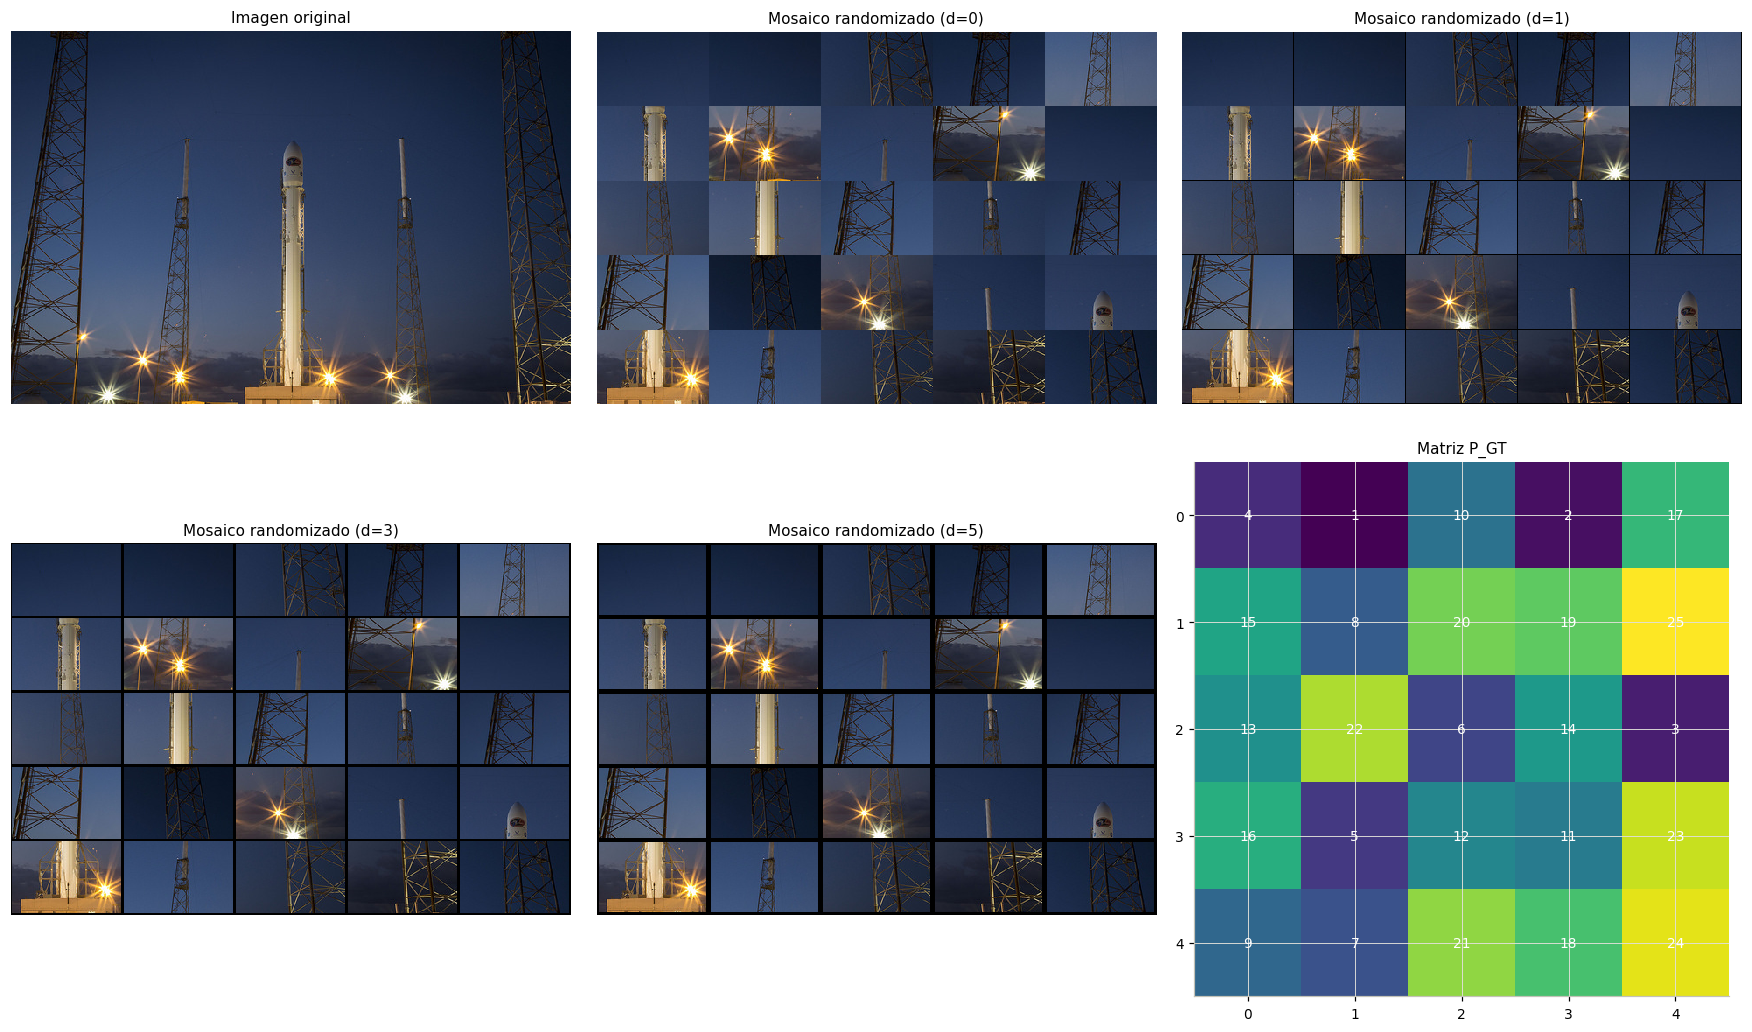

In [96]:
fig, ax = plt.subplots(2, 3, figsize=(16, 10))

# Imagen original
ax[0, 0].imshow(IMAGENES['rocket'])
ax[0, 0].set_title('Imagen original')
ax[0, 0].axis('off')

# Generar mosaicos
for j, d in enumerate([0, 1, 3, 5]):

    mosaico, ground_truth = randomizador_y_gt(
        imagen=IMAGENES['rocket'],
        R=5,
        C=5,
        d=d,
        seed=13
    )

    fila = (j + 1) // 3
    columna = (j + 1) % 3

    ax[fila, columna].imshow(mosaico)
    ax[fila, columna].set_title(f'Mosaico randomizado (d={d})')
    ax[fila, columna].axis('off')

# Matriz P_GT
P_GT = np.array(ground_truth["P_GT"])

ax[1, 2].imshow(P_GT, cmap='viridis')
ax[1, 2].set_title('Matriz P_GT')

for i in range(P_GT.shape[0]):
    for j in range(P_GT.shape[1]):
        ax[1, 2].text(
            j, i, P_GT[i, j],
            ha='center', va='center', color='white'
        )

ax[1, 2].set_xticks(range(P_GT.shape[1]))
ax[1, 2].set_yticks(range(P_GT.shape[0]))

plt.tight_layout()
plt.savefig('resultados/showcase_rocket.png', dpi=300, bbox_inches='tight')
plt.show()

## Estimación automática del interleave  y extracción correcta de los parches

Se crea un vector booleano el cual recibe $s$ tamaño de la celda, $n$ cantidad de celdas y $d$ grosor del interleave.

La función mascara_separación detecta la posiciones donde deberia tener la separación para un determinado d marcando con True las posiciones que deberian ser parte del interleave. Separa el caso de 0 donde todo es false directamente. Para el resto de casos tomamos que sea True para cuando pertenece a los primeros q pixeles del parde y los ulitmos q+1 pixeles del parche.


In [ ]:
def mascara_separacion(s: int, n: int, d: int):

    k = np.arange(n * s) % s
    if d == 0:
        return np.zeros(n * s, dtype=bool)
    q = d // 2
    return (k < q) | (k >= s - q -1)



def estimar_interleave(mosaico, R, C):

    H = mosaico.shape[0]
    W = mosaico.shape[1]

    s_h = H // R
    s_w = W // C
    
    # Identificamos los pixeles que no son negros
    no_nulo = mosaico[:R * s_h, :C * s_w].max(axis=2) > 0
    # Contamos los pixeles no nulos por fila y columna
    por_fila = no_nulo.sum(axis=1)
    por_columna = no_nulo.sum(axis=0)

    diagnostico = []

    # Mascara inicial para d = 0
    previa_f = mascara_separacion(s_h, R, 0)
    previa_c = mascara_separacion(s_w, C, 0)

    # Evaluamos los posibles valores de interleave
    for d in [1, 3, 5]:

        masc_f = mascara_separacion(s_h, R, d)
        masc_c = mascara_separacion(s_w, C, d)

        nuevas_f = masc_f & ~previa_f
        nuevas_c = masc_c & ~previa_c

        # Contamos los pixeles no nulos en las nuevas posiciones
        conteo = int(por_fila[nuevas_f].sum() + por_columna[nuevas_c].sum())
        diagnostico.append(conteo)

        previa_f = masc_f
        previa_c = masc_c
    # Estimamos el interleave
    candidatos = [1, 3, 5]
    d_est = 0
    for i in range(len(candidatos)):
        if diagnostico[i] > 0:
            break
        d_est = candidatos[i]

    return d_est, diagnostico


def extraer_parches(mosaico, R, C, d):

    H = mosaico.shape[0]
    W = mosaico.shape[1]

    s_h = H // R
    s_w = W // C

    # Calculamos los pixeles negros antes del parche y el tamaño util
    q = d // 2
    p_h = s_h - d
    p_w = s_w - d

    # Creamos el arreglo donde guardamos los parches
    parches = np.empty((R * C, p_h, p_w, 3), dtype=mosaico.dtype)

    # Recorremos la grilla de izquierda a derecha y de arriba hacia abajo
    for r in range(R):
        for c in range(C):

            # Indice del parche en el orden de la grilla
            m = r * C + c

            # Esquina superior izquierda del parche util
            fila = r * s_h + q
            columna = c * s_w + q

            parches[m] = mosaico[fila:fila + p_h, columna:columna + p_w]

    return parches



## Test de estimación y extracción de parches

In [83]:
def probar_extraccion(imagen, R, C, seed=13):

    print('Tamaño de la imagen original:', imagen.shape)
    print('R X C =', R,"X" ,C)
    
    for d in [0, 1, 3, 5]:

        print('========== d =', d, '==========')

        mosaico, ground_truth = randomizador_y_gt(imagen=imagen, R=R, C=C, d=d, seed=seed)
        P_GT = np.array(ground_truth["P_GT"])
        d_est, diagnostico = estimar_interleave(mosaico, R, C)

        print("Tamaño del mosaico:", mosaico.shape)
        print('Diagnostico [d=1, d=3, d=5]:', diagnostico)
        print('Interleave estimado:', d_est, '| real:', d)

        parches = extraer_parches(mosaico, R, C, d_est)
        print('Forma del arreglo de parches:', parches.shape)

        # Comparamos cada parche con la imagen original
        H = mosaico.shape[0]
        W = mosaico.shape[1]
        s_h = H // R
        s_w = W // C
        q = d // 2
        p_h = s_h - d
        p_w = s_w - d

        # Crop centrado de la imagen original
        y0 = (imagen.shape[0] - H) // 2
        x0 = (imagen.shape[1] - W) // 2
        crop = imagen[y0:y0 + H, x0:x0 + W]

        iguales = 0
        for r in range(R):
            for c in range(C):

                # Parche del mosaico que va en la posicion (r, c) de la imagen real
                k = P_GT[r, c]

                fila = r * s_h + q
                columna = c * s_w + q
                original = crop[fila:fila + p_h, columna:columna + p_w]

                if np.array_equal(parches[k - 1], original):
                    iguales += 1

        print('Parches identicos al original:', iguales, 'de', R * C)
        assert iguales == R * C
        print()

In [91]:
probar_extraccion(IMAGENES['hubble'], 6, 8)

Tamaño de la imagen original: (872, 1000, 3)
R X C = 6 X 8
========== d = 0 ==========
Tamaño del mosaico: (870, 1000, 3)
Diagnostico [d=1, d=3, d=5]: [12960, 25918, 25920]
Interleave estimado: 0 | real: 0
Forma del arreglo de parches: (48, 145, 125, 3)
Parches identicos al original: 48 de 48

========== d = 1 ==========
Tamaño del mosaico: (870, 1000, 3)
Diagnostico [d=1, d=3, d=5]: [0, 25726, 25728]
Interleave estimado: 1 | real: 1
Forma del arreglo de parches: (48, 144, 124, 3)
Parches identicos al original: 48 de 48

========== d = 3 ==========
Tamaño del mosaico: (870, 1000, 3)
Diagnostico [d=1, d=3, d=5]: [0, 0, 25344]
Interleave estimado: 3 | real: 3
Forma del arreglo de parches: (48, 142, 122, 3)
Parches identicos al original: 48 de 48

========== d = 5 ==========
Tamaño del mosaico: (870, 1000, 3)
Diagnostico [d=1, d=3, d=5]: [0, 0, 0]
Interleave estimado: 5 | real: 5
Forma del arreglo de parches: (48, 140, 120, 3)
Parches identicos al original: 48 de 48

